# Initialisatie van tien geleerde schaalkeuzes — start ×1 tegenover start ×64

**SVHN · CNN-8 · E4M3 → E2M3 → E2M1 · A32 · FP32-masters · B32**

De nieuwe pilot start alle 4.080 schaalparameters op **θ = 0 (factor ×1)**. De bestaande referentie begon op **θ = 6 (factor ×64)**. De tien mogelijkheden ×1–×512 blijven in beide gevallen vrij leerbaar. De bedoelde trainingswijziging is uitsluitend de beginwaarde.

×1 betekent **S_E2 = S_E4**, niet een absolute schaal van 1. De E4M3-bronschaal wordt uit de actuele gewichten berekend. E2M3 en E2M1 delen dezelfde lagere schaal en behouden hun bestaande exponent- en mantissatruncatie.

**Deze pilot stopt uiterlijk na vijf epochs.** Zij laat zien hoe de parameters aanvankelijk bewegen. Zij bepaalt niet of een verre start uiteindelijk naar dezelfde oplossing convergeert. De figuren gebruiken opgeslagen JSON/CSV; er wordt geen training gestart en geen checkpoint geladen.

In [1]:
from pathlib import Path
RUN_DIR = Path('C:\\Users\\renzo\\master-thesis-mx\\mx_runs\\mx_triple_learned_scale10_init1_pilot5\\20261110_174101_905133_joint_run')
SAVE_FIGURES = False


In [2]:
import sys
import importlib.util
import pandas as pd
import matplotlib.pyplot as plt
try:
    from IPython.display import Markdown, display
except ImportError:
    class Markdown(str): pass
    def display(value): print(value)
helper_path = RUN_DIR.expanduser().resolve() / 'notebook_support.py'
if not helper_path.is_file():
    raise FileNotFoundError('Zet RUN_DIR op de resultatenmap van de init×1-pilot: ' + str(helper_path.parent))
spec = importlib.util.spec_from_file_location('_mx_scale10_init1_pilot_analysis', helper_path)
ns = importlib.util.module_from_spec(spec)
sys.modules[spec.name] = ns
spec.loader.exec_module(ns)
run = ns.load_run(RUN_DIR)
figures = {}
display(Markdown(ns.status_markdown(run)))
display(ns.diagnostics_table(run))
display(ns.protocol_table(run))


### Vijf-epochpilot voltooid

Runstatus: **PASS** · laatste afgeronde epoch: **5** · analysefouten: **0**. Historische init×64-vergelijking: **bevestigd**.

Deze proef loopt maximaal vijf epochs. Er is geen epoch-100-resultaat. Lage accuracy is een meetuitkomst; vijf epochs tonen de vroege beweging, niet of een initialisatie uiteindelijk convergeert. De notebook leest alleen JSON/CSV en start geen training.

,Niveau,Melding
0,RUNWAARSCHUWING,The argument 'device' of Tensor.pin_memory() i...
1,RUNWAARSCHUWING,The argument 'device' of Tensor.is_pinned() is...


,Onderdeel,Afspraak
0,Onderzoeksvraag,Beïnvloedt starten bij ×1 in plaats van ×64 he...
1,Enige bedoelde trainingswijziging,Alle 4.080 continue schaalparameters beginnen ...
2,Betekenis ×1,S_E2 = S_E4 × 1 per groep; dit is geen absolut...
3,Tien vrije keuzes,"×1, ×2, ×4, ×8, ×16, ×32, ×64, ×128, ×256, ×512"
4,Gewichtsroute,E4M3-bron → exponent-MSB-truncatie → E2M3 → ma...
5,Leren en grenzen,θ wordt geleerd met de bestaande log-exponent-...
6,Activaties / masters / groepen,A32 / FP32 / B32
7,Leerinstellingen,Adam; gewichts-LR 0.001; schaal-LR 0.001; oors...
8,Vergelijking,Dezelfde oorspronkelijke FP32-/BN-initialisati...
9,Checkpointselectie,Laatste endpoint epoch 5 en eerste hoogste E4M...


## 1. Accuracy gedurende de vijf pilotepochs

Alle drie precisiepanelen delen hun y-as. Het bereik volgt de werkelijk getoonde waarden: als de nieuwe initialisatie lage accuracies oplevert, blijven die zichtbaar. Alleen het beschikbare gemeenschappelijke epochvenster wordt vergeleken. Er wordt geen epoch-100-score getoond of voorspeld.

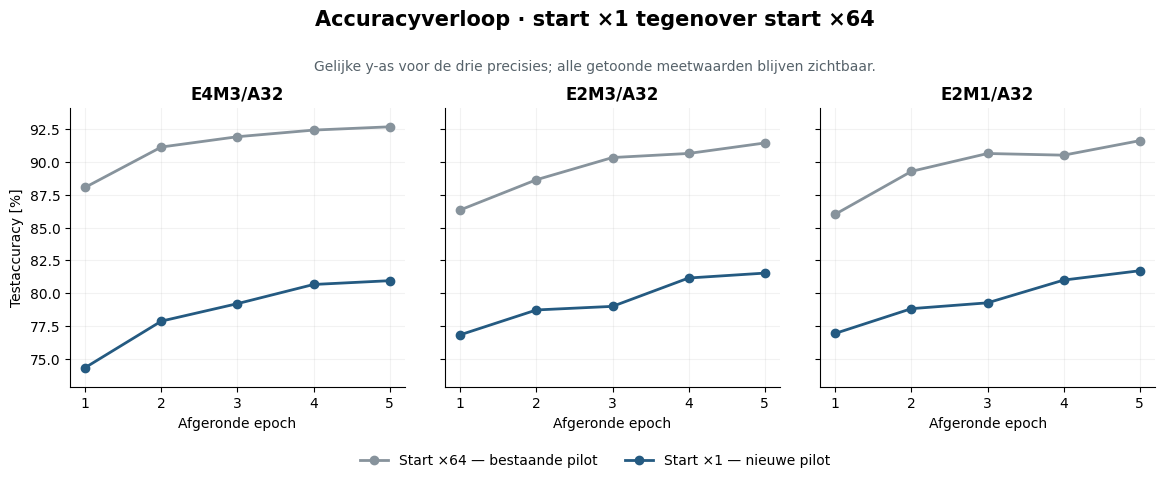

In [3]:
figures['accuracy_verloop'] = ns.plot_initialization_accuracy(run)
display(figures['accuracy_verloop'])
plt.close(figures['accuracy_verloop'])


## 2. Primair piloteindpunt: epoch 5

De vergelijking gebruikt voor beide initialisaties epoch 5. Zij blijft leeg zolang die epoch niet correct beschikbaar is. De gekoppelde punten hebben een duidelijk gemarkeerde ingezoomde as; de twee checkpointfiguren gebruiken dezelfde grenzen.

,Variant,Epoch,Precisie,Testaccuracy [%],Correct,Testbeelden
0,Start ×64 — bestaande pilot,5,E4M3,92.655194,24120,26032
1,Start ×64 — bestaande pilot,5,E2M3,91.425937,23800,26032
2,Start ×64 — bestaande pilot,5,E2M1,91.602643,23846,26032
3,Start ×1 — nieuwe pilot,5,E4M3,80.961893,21076,26032
4,Start ×1 — nieuwe pilot,5,E2M3,81.538107,21226,26032
5,Start ×1 — nieuwe pilot,5,E2M1,81.718654,21273,26032


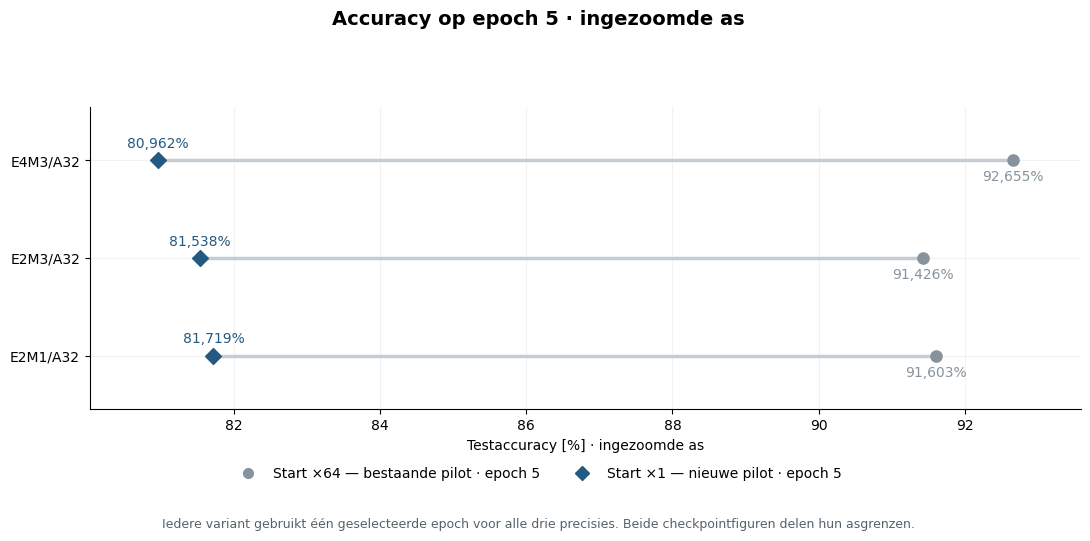

In [4]:
display(ns.initialization_checkpoint_table(run, 'endpoint').drop(columns=['weight_bits']).round({'Testaccuracy [%]': 6}))
figures['accuracy_epoch5'] = ns.plot_initialization_checkpoints(run, 'endpoint')
display(figures['accuracy_epoch5'])
plt.close(figures['accuracy_epoch5'])


## 3. Aanvullend: het E4M3-beste checkpoint

Per variant wordt de eerste hoogste E4M3-testaccuracy in hetzelfde beschikbare venster 1–5 gekozen. Alle drie precisies komen uit die ene geselecteerde epoch. De twee varianten mogen een verschillende beste epoch hebben. Selectie op de officiële testset is geen onafhankelijke validatieschatting.

,Variant,Epoch,Precisie,Testaccuracy [%],Correct,Testbeelden
0,Start ×64 — bestaande pilot,5,E4M3,92.655194,24120,26032
1,Start ×64 — bestaande pilot,5,E2M3,91.425937,23800,26032
2,Start ×64 — bestaande pilot,5,E2M1,91.602643,23846,26032
3,Start ×1 — nieuwe pilot,5,E4M3,80.961893,21076,26032
4,Start ×1 — nieuwe pilot,5,E2M3,81.538107,21226,26032
5,Start ×1 — nieuwe pilot,5,E2M1,81.718654,21273,26032


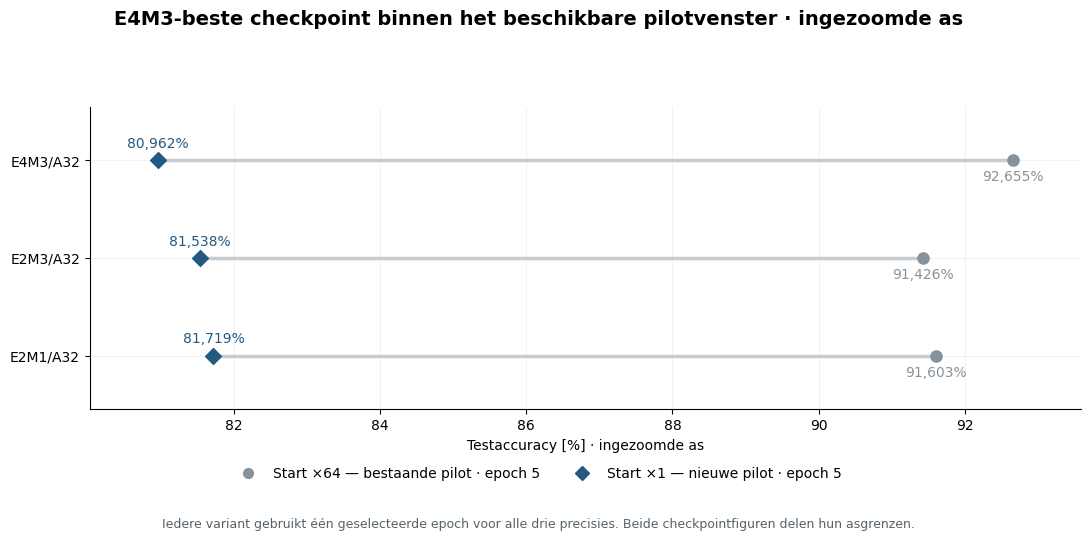

In [5]:
display(ns.initialization_checkpoint_table(run, 'best').drop(columns=['weight_bits']).round({'Testaccuracy [%]': 6}))
figures['accuracy_best_E4M3'] = ns.plot_initialization_checkpoints(run, 'best')
display(figures['accuracy_best_E4M3'])
plt.close(figures['accuracy_best_E4M3'])


## 4. Evolutie van alle tien schaalfactoren

Epoch 0 is de werkelijk opgeslagen initialisatie. De heatmap houdt alle factoren zichtbaar, inclusief nulpercentages. Een factor kan gelijk blijven terwijl θ al beweegt binnen het bijbehorende afrondingsinterval.

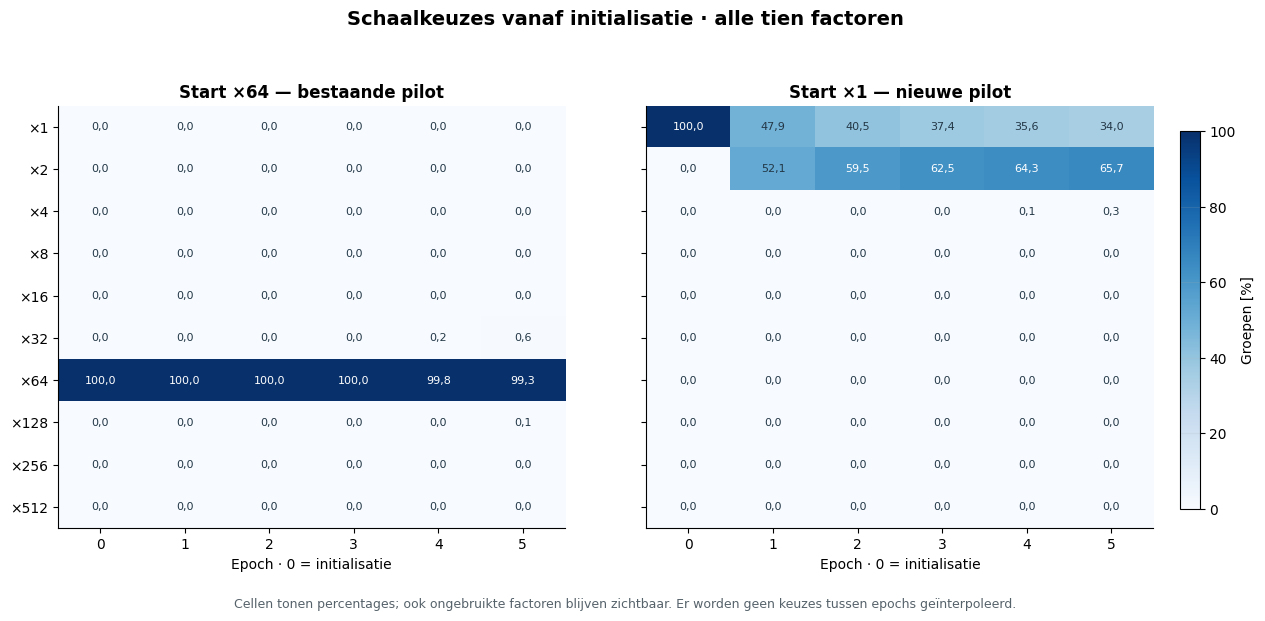

In [6]:
figures['factoren_per_epoch'] = ns.plot_factor_evolution(run)
display(figures['factoren_per_epoch'])
plt.close(figures['factoren_per_epoch'])


## 5. Groepen en percentages aan het begin en einde

De staafgrafieken beginnen op nul en tonen aantallen én aandelen. De historische eindverdeling gebruikt dezelfde afgeronde epoch als de nieuwe pilot. De E4M3-bronschaal blijft hierbij dynamisch.

,Epoch,Factor,Groepen,Aandeel [%]
0,0,×1,4080,100.0
1,0,×2,0,0.0
2,0,×4,0,0.0
3,0,×8,0,0.0
4,0,×16,0,0.0
5,0,×32,0,0.0
6,0,×64,0,0.0
7,0,×128,0,0.0
8,0,×256,0,0.0
9,0,×512,0,0.0


,Epoch,Factor,Groepen,Aandeel [%]
0,5,×1,1389,34.0441
1,5,×2,2679,65.6618
2,5,×4,12,0.2941
3,5,×8,0,0.0000
4,5,×16,0,0.0000
5,5,×32,0,0.0000
6,5,×64,0,0.0000
7,5,×128,0,0.0000
8,5,×256,0,0.0000
9,5,×512,0,0.0000


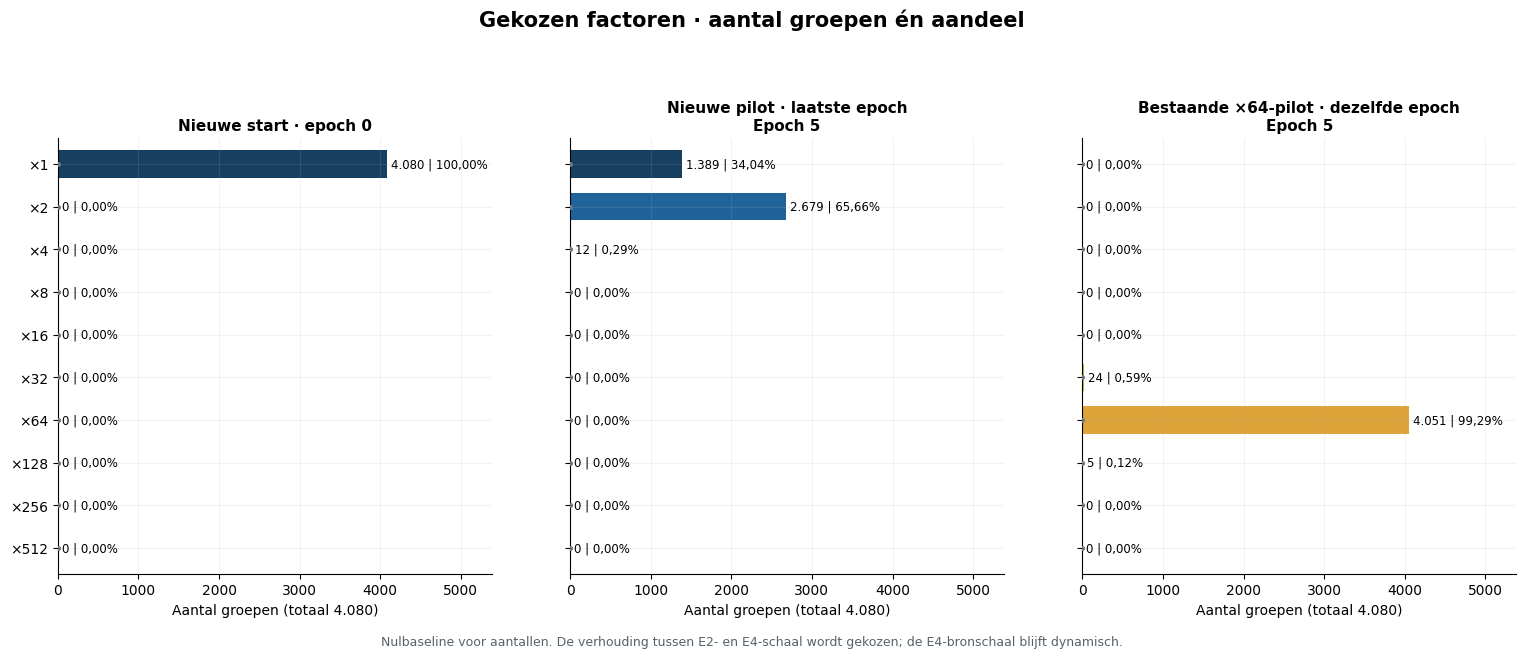

In [7]:
display(ns.factor_distribution_table(run, 0).round({'Aandeel [%]': 4}))
display(ns.factor_distribution_table(run).round({'Aandeel [%]': 4}))
figures['factoren_aantallen'] = ns.plot_factor_counts(run)
display(figures['factoren_aantallen'])
plt.close(figures['factoren_aantallen'])


## 6. Continue θ-beweging vóór een harde factorwissel

De optimizer past een continue FP32-parameter aan; de voorwaartse stap rondt die naar een integeroffset af. De schaal-LR blijft 0,001. Starten op θ=0 ligt ver van θ=6; vijf epochs zijn daarom geen voldoende grond om te besluiten dat de uiteindelijke oplossing niet bereikbaar is. Er geldt geen veronderstelde harde Adam-stapgrens.

,Epoch,Laag,Groepen,Min θ,P05 θ,Mediaan θ,Gemiddelde θ,P95 θ,Max θ,Exact θ=0 [%],Factor ×1 [%]
0,0,Alle lagen,4080,0.0,0.000000,0.000000,0.000000,0.000000,0.000000,100.000000,100.000000
7,1,Alle lagen,4080,0.0,0.004649,0.518278,0.460229,0.799248,1.029195,1.691176,47.916667
14,2,Alle lagen,4080,0.0,0.008806,0.615371,0.560502,1.013538,1.337014,0.980392,40.490196
21,3,Alle lagen,4080,0.0,0.013098,0.668812,0.615044,1.128022,1.502223,0.686275,37.426471
28,4,Alle lagen,4080,0.0,0.012071,0.696198,0.647304,1.200259,1.650548,1.004902,35.588235
35,5,Alle lagen,4080,0.0,0.011128,0.711870,0.665013,1.229894,1.752944,1.200980,34.044118


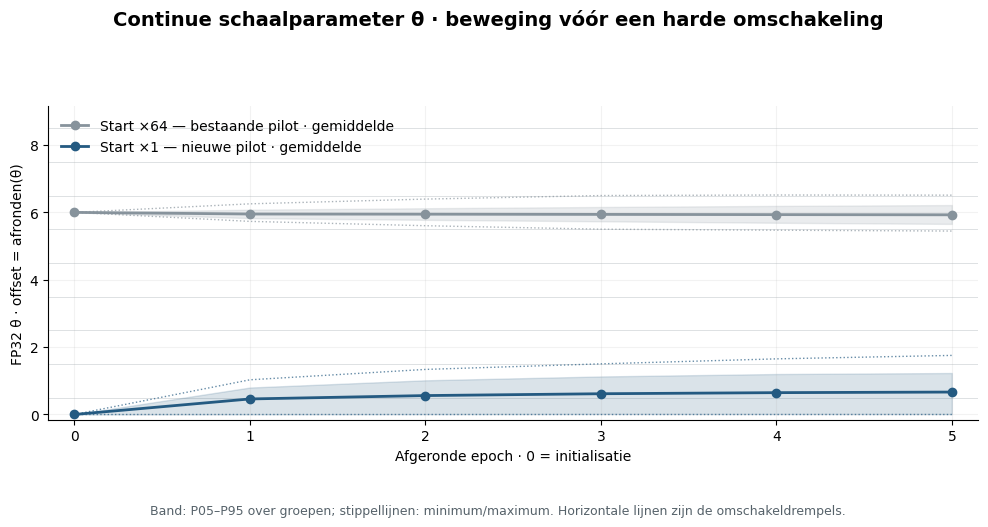

In [8]:
theta = ns.theta_summary_table(run)
display(theta.loc[theta.Laag.eq('Alle lagen')].round(6))
figures['theta_totaal'] = ns.plot_theta_evolution(run)
display(figures['theta_totaal'])
plt.close(figures['theta_totaal'])


## 7. Continue parameters per MX-laag

De zes panelen delen hun y-as. Gemiddelde, P05–P95 en minimum/maximum tonen of de beweging in bepaalde lagen zit. Er worden geen conclusies over vastlopen getrokken uit uitsluitend de harde schaalkeuzes.

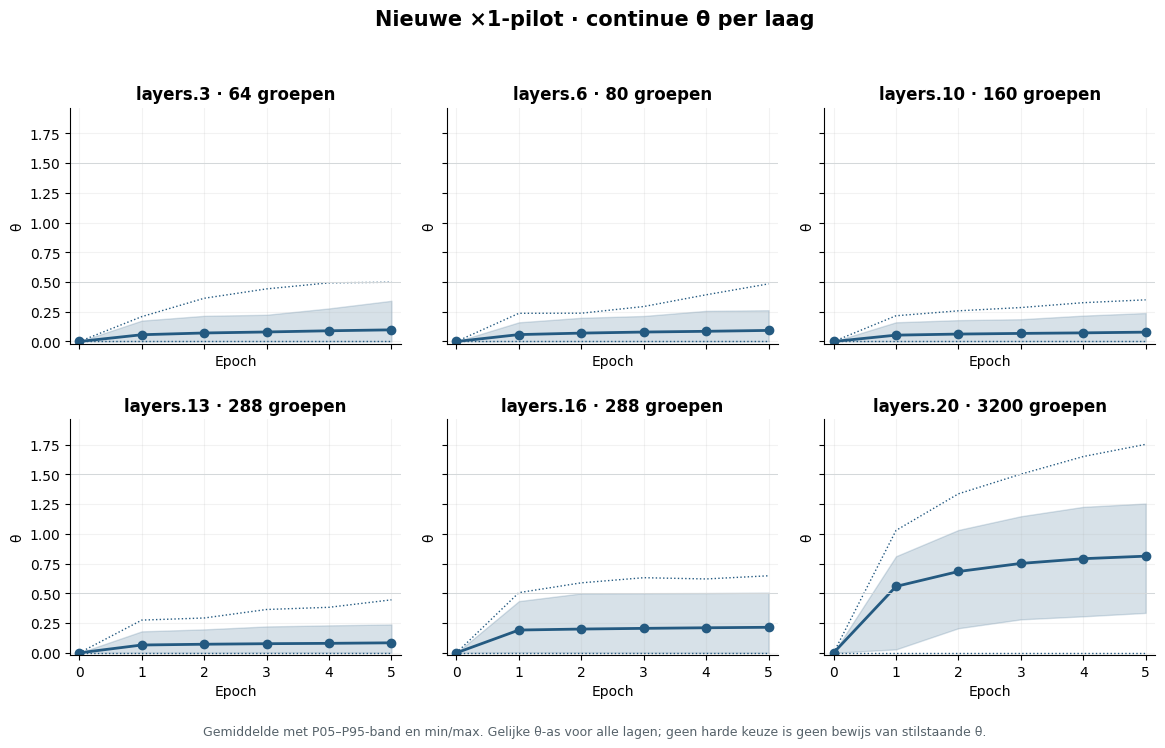

,Epoch,Laag,Gemiddelde θ,Min θ,Max θ,Exact θ=0 [%],Factor ×1 [%]
1,0,layers.10,0.000000,0.0,0.000000,100.000000,100.000000
2,0,layers.13,0.000000,0.0,0.000000,100.000000,100.000000
3,0,layers.16,0.000000,0.0,0.000000,100.000000,100.000000
4,0,layers.20,0.000000,0.0,0.000000,100.000000,100.000000
5,0,layers.3,0.000000,0.0,0.000000,100.000000,100.000000
6,0,layers.6,0.000000,0.0,0.000000,100.000000,100.000000
8,1,layers.10,0.053319,0.0,0.216322,7.500000,100.000000
9,1,layers.13,0.065740,0.0,0.275128,2.777778,100.000000
10,1,layers.16,0.191594,0.0,0.506240,3.125000,98.958333
11,1,layers.20,0.558381,0.0,1.029195,0.968750,33.687500


In [9]:
figures['theta_per_laag'] = ns.plot_theta_by_layer(run)
display(figures['theta_per_laag'])
plt.close(figures['theta_per_laag'])

# Per laag en epoch: een harde ×1-keuze is iets anders dan exact θ=0.
display(theta.loc[theta.Laag.ne('Alle lagen'), ['Epoch', 'Laag', 'Gemiddelde θ', 'Min θ', 'Max θ', 'Exact θ=0 [%]', 'Factor ×1 [%]']].round(6))


## 8. ×1 kiezen is niet hetzelfde als op de ondergrens vastzitten

Factor ×1 geldt zolang θ naar offset 0 wordt afgerond. **Exact θ=0** betekent dat de parameter op de projectiegrens staat. Adam kan θ vanuit 0 omhoog bewegen; updates onder 0 worden terug op de ondergrens geprojecteerd. Eén groep kan binnen een epoch meermaals worden geprojecteerd.

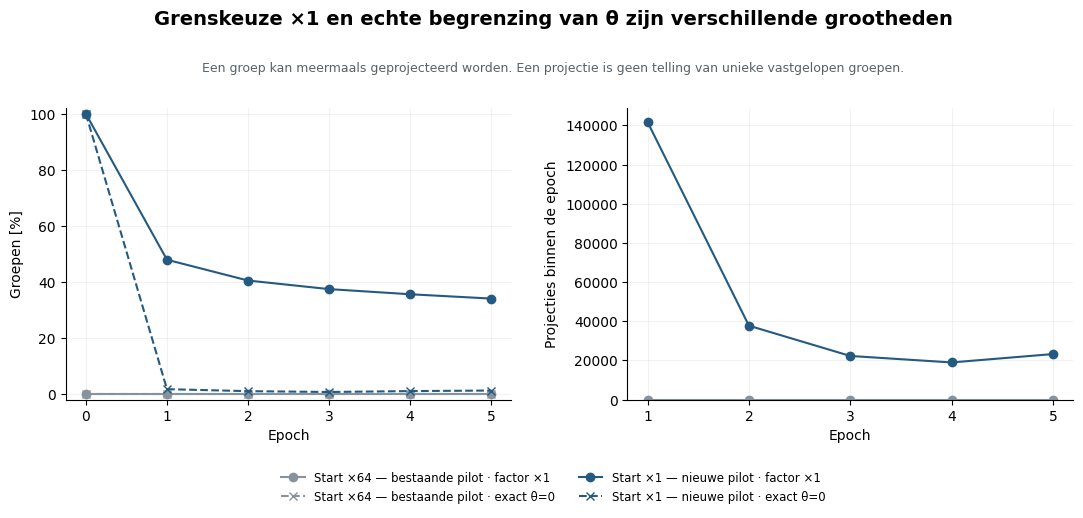

In [10]:
figures['grenzen_en_projecties'] = ns.plot_initialization_boundaries(run)
display(figures['grenzen_en_projecties'])
plt.close(figures['grenzen_en_projecties'])


## 9. Gradients, echte updates en omschakelingen

Vergelijk het aantal gewijzigde FP32-parameters, de netto θ-verplaatsing, harde omschakelingen en de geregistreerde gradientnorm. De gradientfiguur toont de grootste **laag**-norm over alle batches; zij is geen globale gradientnorm van het hele netwerk. Flips en unieke wisselende groepen worden apart geteld.

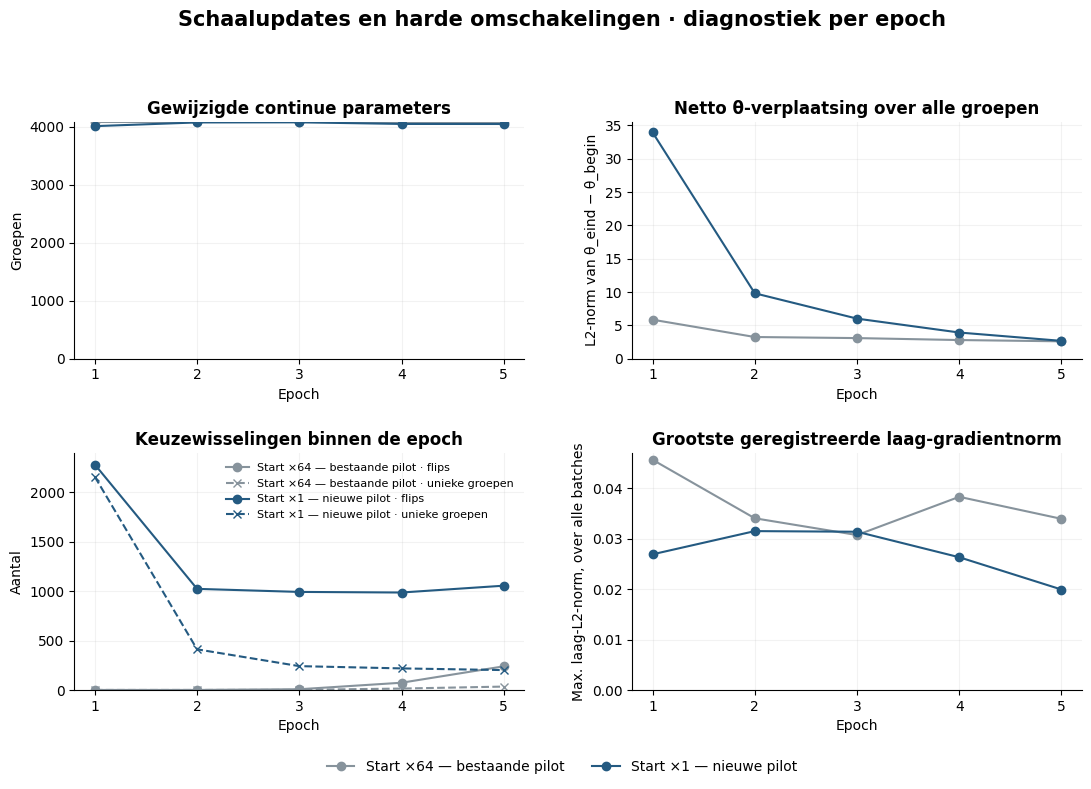

In [11]:
figures['updates_en_gradients'] = ns.plot_initialization_updates(run)
display(figures['updates_en_gradients'])
plt.close(figures['updates_en_gradients'])


## 10. Kosten, duur en interpretatie

De gewijzigde beginwaarde voegt geen extra schaalopties, parameters of passes toe. De opslag hieronder is analytisch; het zijn geen gemeten hardware-energiecijfers. Vergelijk de gemeten duur descriptief met de bestaande pilot.

**Beoordeling:** bekijk of θ vanaf ×1 beweegt, of de verdeling verschuift, en hoe de drie accuracies volgen. Een weinig bewegende verdeling na vijf epochs kan samenhangen met de afstand tot andere offsets, de leersnelheid of projectie op de grens. Een slechte korte run bewijst niet dat ×64 globaal optimaal is. Gelijke seeds en gecontroleerde datavolgordes geven bij de bestaande CUDA-instellingen geen bitexacte reproduceerbaarheid.

In [12]:
display(ns.initialization_cost_table(run))
if not run.times.empty:
    display(run.times[['epoch', 'train_seconds', 'test_seconds', 'total_epoch_seconds']].round(3))
display(Markdown(ns.scale_learning_markdown(run)))


,Onderdeel,Waarde,Betekenis
0,FP32 schaalparameters,4080,Beide initialisaties hebben hetzelfde aantal t...
1,Gepakte keuze-informatie [bytes],2040,"Vier bits per B32-groep, tien mogelijke offsets."
2,θ + gradient + twee Adam-momenten [bytes],65280,Analytisch 4 × 4.080 × 4; exclusief framework ...
3,Nieuwe trainingspasses per minibatch,3,E4M3 → E2M3 → E2M1; dezelfde route als de init...


,epoch,train_seconds,test_seconds,total_epoch_seconds
0,1,53.930,11.683,65.884
1,2,45.967,12.025,58.170
2,3,46.861,11.853,58.889
3,4,47.360,12.206,59.747
4,5,47.233,12.172,59.584


**Laatste afgeronde epoch 5 — aantallen per factor:** ×1: **1,389**, ×2: **2,679**, ×4: **12**, ×8: **0**, ×16: **0**, ×32: **0**, ×64: **0**, ×128: **0**, ×256: **0**, ×512: **0**. Totaal: 4,080 groepen. In de laatste epoch veranderden 4,048 FP32-hulpwaarden. Over de opgeslagen training werden 6,337 harde keuzewisselingen geteld.

**Uiterste keuzes:** 1,389 groepen kiezen ×1 en 0 kiezen ×512. **Exact op de projectiegrens:** 49 θ-waarden zijn 0 en 0 zijn 9. Een uiterste keuze betekent dus niet automatisch dat de continue parameter op de grens vastzit.

Een groep kan binnen een epoch meerdere keren wisselen. Het aantal wissels, het aantal unieke wisselende groepen en het verschil tussen de twee epochgrenzen zijn afzonderlijke metingen. Een sprong van offset5 naar7 telt als één wissel met sprongafstand2. Geen harde wissel sluit een continue θ-verplaatsing niet uit; geen van deze diagnostieken bewijst accuracywinst.

## Optioneel: figuren bewaren

Deze notebook blijft standaard alleen lezen en weergeven. Zet bovenaan `SAVE_FIGURES = True` om de figuren en bronverwijzingen in een nieuwe analysemap te bewaren.

In [13]:
if SAVE_FIGURES:
    destination = ns.save_figures(figures, run)
    print('Figuren opgeslagen in:', destination)
else:
    print('Alleen gelezen en weergegeven; bestaande resultaten zijn ongewijzigd.')


Alleen gelezen en weergegeven; bestaande resultaten zijn ongewijzigd.
